# 02 · Clean the data and build the variables

Input: `data/raw/`. Output: `data/processed/panel.csv`, one row per stock per trading day, with

- the forecast target (next week's realized variance),
- the HAR inputs (today, past week, past month),
- the geopolitical risk variables, lagged so that only information available at the close of day *t* is used.

Every cleaning decision is listed below with the number of rows it affects.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from helpers import (TICKERS, SAMPLE_START, TRAIN_END, DATA_PROC, FIGURES,
                     load_prices, load_gpr, har_components)

pd.set_option("display.float_format", "{:.3f}".format)

## 1. Prices: cleaning

Two rules, applied to each series separately (each exchange has its own holidays, so the series are **not** forced onto a common calendar):

1. **Missing close:** rows without a closing price are dropped.
2. **Non-trading days:** Yahoo sometimes includes exchange holidays as rows with zero volume and the previous day's price. A row is dropped when volume is zero *and* the close equals the previous close. A genuine zero-return day with trading volume is kept. (The index has no volume, so for it only the repeated-price condition matters.)

In [2]:
def clean_prices(p):
    log = {"raw rows": len(p)}
    p = p.dropna(subset=["Close"])
    log["missing close"] = log["raw rows"] - len(p)
    stale = (p["Volume"].fillna(0) == 0) & (p["Close"] == p["Close"].shift(1))
    p = p[~stale]
    log["non-trading days"] = int(stale.sum())
    log["rows kept"] = len(p)
    return p, log

prices, logs = {}, {}
for t in TICKERS:
    prices[t], logs[t] = clean_prices(load_prices(t))

pd.DataFrame(logs).T

,raw rows,missing close,non-trading days,rows kept
RHM.DE,5552,0,9,5543
LDO.MI,5410,0,3,5407
BA.L,5524,0,9,5515
HO.PA,5589,0,5,5584
SAAB-B.ST,5503,0,23,5480
AM.PA,5589,0,16,5573
^STOXX50E,4911,0,5,4906


## 2. Returns

Daily log return in percent: rₜ = 100 · ln(Pₜ / Pₜ₋₁).

Very large moves are **listed, not removed**: in this project the extreme days (e.g. the invasion of Ukraine) are exactly the ones that matter. Each one is checked against the news before the data is trusted.

In [3]:
returns = {t: (100 * np.log(prices[t]["Close"]).diff()).dropna() for t in TICKERS}

big = pd.concat({TICKERS[t][1]: r[r.abs() > 15] for t, r in returns.items()}).rename("return %")
print(f"Days with |r| > 15%: {len(big)}")
big.to_frame()

Days with |r| > 15%: 19


return %
                  Date                
Rheinmetall       2008-12-08    15.906
                  2020-03-20    18.957
                  2022-02-28    22.155
                  2022-03-01    15.884
                  2026-06-24   -20.644
Leonardo          2011-07-28   -19.068
                  2011-09-14    15.605
                  2011-11-15   -22.728
                  2017-11-10   -24.265
                  2020-03-12   -25.039
                  2020-11-09    15.072
Saab              2008-09-04   -21.730
                  2009-02-13   -17.613
                  2013-12-19    27.672
                  2018-10-23   -16.880
                  2020-10-19   -15.440
                  2022-02-28    16.616
                  2025-07-18    15.210
Dassault Aviation 2012-01-31    16.944

In [4]:
pd.DataFrame({
    TICKERS[t][1]: {
        "first day": r.index.min().date(),
        "last day": r.index.max().date(),
        "days": len(r),
        "zero returns": int((r == 0).sum()),
        "ann. vol %": r.std() * np.sqrt(252),
    } for t, r in returns.items()
}).T

,first day,last day,days,zero returns,ann. vol %
Rheinmetall,2005-01-04,2026-10-30,5542,45,37.913
Leonardo,2005-07-19,2026-10-30,5406,63,37.264
BAE Systems,2005-01-04,2026-10-30,5514,91,25.566
Thales,2005-01-04,2026-10-30,5583,62,25.599
Saab,2005-01-04,2026-10-30,5479,195,34.208
Dassault Aviation,2005-01-04,2026-10-30,5572,254,28.224
EURO STOXX 50,2007-04-02,2026-10-30,4905,0,21.737


## 3. Realized variance and the HAR inputs

With daily data, the variance of day *t* is proxied by rₜ². Following Corsi (2009), three horizons:

- RVᵈₜ = rₜ²  (today)
- RVʷₜ = mean of rₜ₋₄², …, rₜ²  (past week)
- RVᵐₜ = mean of rₜ₋₂₁², …, rₜ²  (past month)

**Target:** RVₜ₊₁:ₜ₊₅ = mean of rₜ₊₁², …, rₜ₊₅², the realized variance of the next five trading days. Using the mean rather than the sum only shifts ln RV by the constant ln 5.

**Logs.** The models use ln RV. A day with rₜ = 0 gives ln 0 = −∞, so zeros are replaced by the smallest positive value of that stock (the count is in the table above). Weekly and monthly averages are never zero in practice.

In [5]:
RV_COLS = ["rv_d", "rv_w", "rv_m", "rv_fwd"]

har = {}
for t, r in returns.items():
    h = har_components(r)
    h.insert(0, "r", r)
    floor = (r[r != 0] ** 2).min()
    for c in RV_COLS:
        h["log_" + c] = np.log(h[c].clip(lower=floor))
    har[t] = h

har["RHM.DE"].dropna().head()

,r,rv_d,rv_w,rv_m,rv_fwd,log_rv_d,log_rv_w,log_rv_m,log_rv_fwd
Date,,,,,,,,,
2005-02-02,0.621,0.386,0.583,1.240,2.142,-0.952,-0.540,0.215,0.762
2005-02-03,-0.896,0.803,0.471,1.228,1.984,-0.220,-0.754,0.205,0.685
2005-02-04,2.347,5.510,1.345,1.478,1.434,1.706,0.296,0.391,0.360
2005-02-07,0.220,0.048,1.354,1.453,1.424,-3.033,0.303,0.374,0.354
2005-02-08,-0.342,0.117,1.373,1.431,2.047,-2.148,0.317,0.358,0.716


## 4. Geopolitical risk: timing

The GPR of calendar day *d* counts articles published on day *d*, so it is only complete **after** day *d*. A forecast made at the close of trading day *t* may therefore use GPR up to calendar day *t − 1* only. Using day *t* would leak information into the forecast.

Two versions of each series (total, Acts, Threats):

- `_d`: value on calendar day *t − 1*
- `_w`: mean over the 7 calendar days *t − 7*, …, *t − 1*. This also covers weekend news before a Monday.

The index is very skewed (rare days above 500), so the models will use ln(1 + GPR). The `+1` handles the few days on which the index is 0.

In [6]:
g = load_gpr().asfreq("D")
print("GPR:", g.index.min().date(), "->", g.index.max().date(), "| missing calendar days:", int(g.isna().any(axis=1).sum()))
print("Days equal to 0:", (g == 0).sum().to_dict())

gpr_feat = pd.concat([
    np.log1p(g.shift(1)).add_suffix("_d"),                   # day t-1
    np.log1p(g.rolling(7).mean().shift(1)).add_suffix("_w"), # mean of t-7 ... t-1
], axis=1)

print("Correlation of Acts and Threats since 2007 (daily, levels):",
      round(g.loc[SAMPLE_START:, "acts"].corr(g.loc[SAMPLE_START:, "threats"]), 2))
gpr_feat.loc[SAMPLE_START:].head()

GPR: 1985-01-01 -> 2026-10-05 | missing calendar days: 0
Days equal to 0: {'gpr': 2, 'acts': 86, 'threats': 13}
Correlation of Acts and Threats since 2007 (daily, levels): 0.49


,gpr_d,acts_d,threats_d,gpr_w,acts_w,threats_w
date,,,,,,
2007-01-01,3.663,3.941,3.093,4.601,4.504,4.614
2007-01-02,4.514,4.628,4.332,4.531,4.478,4.507
2007-01-03,4.751,4.710,4.672,4.514,4.507,4.465
2007-01-04,4.353,4.634,3.773,4.519,4.583,4.378
2007-01-05,4.459,4.809,3.728,4.492,4.595,4.276


## 5. Build the panel

Each stock keeps its own trading days, and the GPR variables are attached by date. The sample starts on 1 January 2007 (after the 22-day warm-up of RVᵐ). It ends on the last day with both a complete target week and GPR data.

**Split:** training 2007–2019, test 2020 onwards. The models in notebook 03 are estimated with a rolling window inside this test period, so the split is only used to mark the first forecast date.

In [7]:
frames = []
for t, h in har.items():
    df = h.join(gpr_feat, how="left")
    df = df.loc[SAMPLE_START:].dropna()
    df.insert(0, "ticker", t)
    df.insert(1, "name", TICKERS[t][1])
    df.insert(2, "group", TICKERS[t][2])
    frames.append(df)

panel = pd.concat(frames)
panel.index.name = "date"
panel["split"] = np.where(panel.index <= TRAIN_END, "train", "test")

p = panel.reset_index()
p.groupby("name", sort=False).agg(
    first=("date", "min"),
    last=("date", "max"),
    train_days=("split", lambda s: (s == "train").sum()),
    test_days=("split", lambda s: (s == "test").sum()),
)

,first,last,train_days,test_days
name,,,,
Rheinmetall,2007-01-02,2026-10-05,3291,1721
Leonardo,2007-01-02,2026-10-05,3296,1720
BAE Systems,2007-01-02,2026-10-05,3284,1707
Thales,2007-01-02,2026-10-05,3321,1732
Saab,2007-01-02,2026-10-05,3257,1700
Dassault Aviation,2007-01-02,2026-10-05,3310,1732
EURO STOXX 50,2007-05-04,2026-10-05,3164,1701


## 6. Checks

**Stationarity (ADF test).** The HAR is a regression in levels, so ln RV and ln(1 + GPR) should be stationary. The ADF null hypothesis is a unit root, so a small p-value means stationary.

In [8]:
from statsmodels.tsa.stattools import adfuller

rows = {}
for t in TICKERS:
    s = panel.loc[panel.ticker == t, "log_rv_w"]
    rows[f"ln RV week, {TICKERS[t][1]}"] = adfuller(s, autolag="AIC")[:2]
gpr_sample = gpr_feat.loc[SAMPLE_START:panel.index.max()]
for c in ["gpr_d", "acts_d", "threats_d"]:
    rows[f"ln(1+{c})"] = adfuller(gpr_sample[c].dropna(), autolag="AIC")[:2]

pd.DataFrame(rows, index=["ADF statistic", "p-value"]).T

/var/folders/0g/17259zyn44qft1hc6wcq3mlc0000gn/T/ipykernel_67680/1709530861.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows[f"ln RV week, {TICKERS[t][1]}"] = adfuller(s, autolag="AIC")[:2]
/var/folders/0g/17259zyn44qft1hc6wcq3mlc0000gn/T/ipykernel_67680/1709530861.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows[f"ln RV week, {TICKERS[t][1]}"] = adfuller(

,ADF statistic,p-value
"ln RV week, Rheinmetall",-6.405,0.000
"ln RV week, Leonardo",-9.798,0.000
"ln RV week, BAE Systems",-8.270,0.000
"ln RV week, Thales",-8.139,0.000
"ln RV week, Saab",-8.597,0.000
"ln RV week, Dassault Aviation",-9.378,0.000
"ln RV week, EURO STOXX 50",-7.663,0.000
ln(1+gpr_d),-5.928,0.000
ln(1+acts_d),-5.547,0.000
ln(1+threats_d),-5.869,0.000


**Figure 1: the data at a glance.** Top: 30-day average of GPR Threats and Acts. Bottom: annualised volatility over the past month, √(252 · RVᵐ), for Rheinmetall, the average of the six defence stocks, and the EURO STOXX 50.

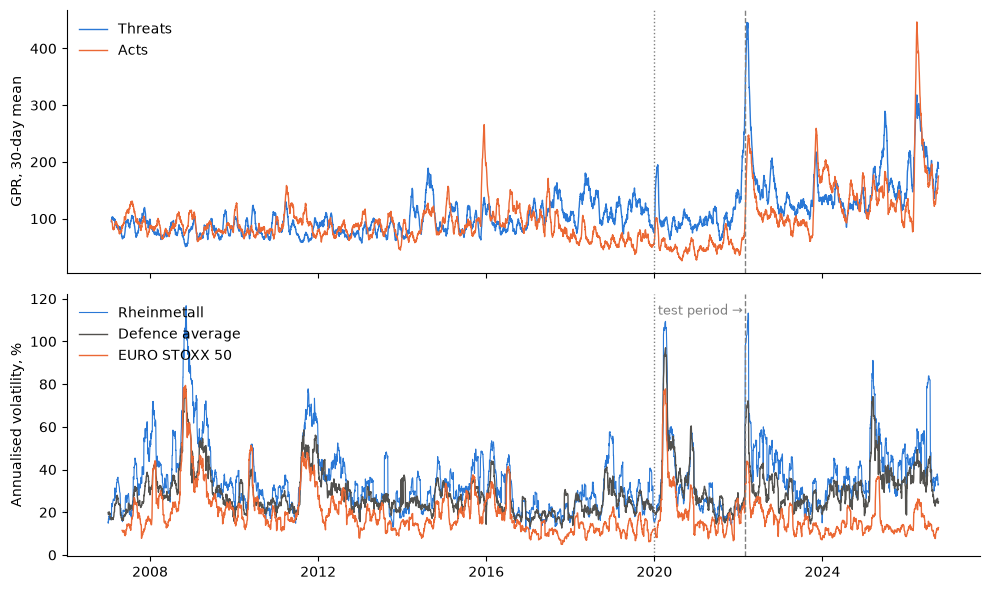

In [9]:
vol = panel.pivot_table(index="date", columns="ticker", values="rv_m")
vol = np.sqrt(252 * vol)
defence = [t for t in TICKERS if TICKERS[t][2] == "defence"]

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
g30 = g.loc[SAMPLE_START:panel.index.max()].rolling(30).mean()
ax[0].plot(g30.index, g30["threats"], color="#2a78d6", lw=1, label="Threats")
ax[0].plot(g30.index, g30["acts"], color="#eb6834", lw=1, label="Acts")
ax[0].set_ylabel("GPR, 30-day mean")
ax[0].legend(loc="upper left", frameon=False)

rhm = vol["RHM.DE"].dropna()   # each stock has its own holidays: drop the gaps before plotting
ax[1].plot(rhm.index, rhm, color="#2a78d6", lw=0.8, label="Rheinmetall")
ax[1].plot(vol.index, vol[defence].mean(axis=1), color="#52514e", lw=1, label="Defence average")
mkt = vol["^STOXX50E"].dropna()
ax[1].plot(mkt.index, mkt, color="#eb6834", lw=1, label="EURO STOXX 50")
ax[1].set_ylabel("Annualised volatility, %")
ax[1].legend(loc="upper left", frameon=False)

for a in ax:
    a.axvline(pd.Timestamp("2020-01-01"), color="grey", ls=":", lw=1)
    a.axvline(pd.Timestamp("2022-02-24"), color="grey", ls="--", lw=1)
    a.spines[["top", "right"]].set_visible(False)
ax[1].text(pd.Timestamp("2020-02-01"), ax[1].get_ylim()[1] * 0.92, "test period →", color="grey", fontsize=9)

fig.tight_layout()
fig.savefig(FIGURES / "fig01_data_overview.png", dpi=200)
plt.show()

## 7. Save

In [10]:
out = DATA_PROC / "panel.csv"
panel.to_csv(out, float_format="%.6g")
print(f"Saved {out.relative_to(DATA_PROC.parents[1])}: {len(panel):,} rows, {panel.shape[1]} columns")
print(list(panel.columns))

Saved data/processed/panel.csv: 34,936 rows, 19 columns
['ticker', 'name', 'group', 'r', 'rv_d', 'rv_w', 'rv_m', 'rv_fwd', 'log_rv_d', 'log_rv_w', 'log_rv_m', 'log_rv_fwd', 'gpr_d', 'acts_d', 'threats_d', 'gpr_w', 'acts_w', 'threats_w', 'split']
